# Módulo 9 — Opções americanas por simulação: LSM e dual

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 7 do livro.

## O que você vai conseguir fazer ao final

1. Formular o valor de uma americana como problema de parada ótima e como programação dinâmica.
2. Explicar por que a simulação, que anda para a frente, tem dificuldade com um problema que anda para trás.
3. Entender o algoritmo de Longstaff-Schwartz como uma projeção, e implementá-lo.
4. Distinguir os vieses para cima e para baixo do LSM, e evitá-los.
5. Deduzir a formulação dual e obter um limite superior.
6. Construir um intervalo de confiança para o valor americano com os dois limites.
7. Comparar os resultados com a referência certa: o valor bermudano.

## Onde estamos

No Módulo 6, a árvore resolveu a put americana com um único `max` por nó. Mas árvores ficam inviáveis com várias variáveis de estado, como no modelo geral que vamos usar (índice, variância e juros). A simulação não sofre com a dimensão, mas anda no sentido errado. Este módulo resolve esse impasse.

## 0. Preparação

In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial import polynomial as P
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


# Os dois exemplos do livro
PUT = dict(S0=36.0, K=40.0, T=1.0, r=0.06, sig=0.20)
CONDOR = dict(S0=100.0, K=100.0, T=1.0, r=0.05, sig=0.50)
pay_put = lambda s: np.maximum(40.0 - s, 0.0)
pay_condor = lambda s: np.minimum(40.0, np.maximum(90.0 - s, 0.0) + np.maximum(s - 110.0, 0.0))
print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O problema

**Livro: §7.3.1**

### 1.1 Parada ótima

O titular de uma americana escolhe **quando** exercer. Essa escolha só pode usar a informação disponível até o momento: é um **tempo de parada**, no sentido do Módulo 3. O valor é o melhor resultado possível entre todos os tempos de parada:

$$V_0 = \sup_{\tau}\ \mathbb{E}^Q\big[e^{-r\tau}h(S_\tau)\big].$$

### 1.2 Programação dinâmica

Para calcular, discretizamos o tempo em $M$ datas de exercício, $t_m = m\Delta t$. Na última data, $V_M = h(S_M)$. Nas anteriores, comparamos o exercício com o **valor de continuação**:

$$C_m(s) = \mathbb{E}^Q\big[e^{-r\Delta t}V_{m+1}(S_{m+1})\,\big|\,S_m = s\big], \qquad V_m(s) = \max\big[h(s),\ C_m(s)\big].$$

O processo $V_m$ é a **envoltória de Snell**: o menor supermartingale que fica acima do payoff descontado.

### 1.3 Americana ou bermudana?

Com $M$ datas, o algoritmo precifica uma **bermudana** de $M$ datas, e não a americana com exercício contínuo. A diferença é sistemática e sempre para baixo. No Módulo 6 vimos que, para a put de Longstaff-Schwartz, a diferença com 50 datas é de cerca de 0,009.

Isso tem uma consequência para a leitura dos resultados: **um algoritmo com $M$ datas deve ser comparado com a bermudana de $M$ datas**. Comparar com a americana mistura dois erros diferentes.

### Laboratório 1.1 — As referências corretas

Calculamos por árvore (Módulo 6) o valor bermudano para as datas usadas no livro e o valor americano.

In [2]:
def arvore_bermudana(pay, S0, T, r, sig, datas, fator=200, guardar=False):
    """Árvore CRR com 'fator' passos entre datas de exercício. Opcionalmente guarda V nas datas."""
    N = datas * fator
    dt = T / N
    u = np.exp(sig * np.sqrt(dt))
    d = 1 / u
    q = (np.exp(r * dt) - d) / (u - d)
    desc = np.exp(-r * dt)
    j = np.arange(N + 1)
    ST = S0 * u**j * d ** (N - j)
    V = pay(ST)
    tab = {datas: (np.log(ST), V.copy())} if guardar else None
    for t in range(N - 1, -1, -1):
        V = desc * (q * V[1:] + (1 - q) * V[:-1])
        if t % fator == 0 and t > 0:
            j = np.arange(t + 1)
            St = S0 * u**j * d ** (t - j)
            V = np.maximum(V, pay(St))
            if guardar:
                tab[t // fator] = (np.log(St), V.copy())
    return (float(V[0]), tab) if guardar else float(V[0])


p_ = dict(S0=PUT["S0"], T=PUT["T"], r=PUT["r"], sig=PUT["sig"])
c_ = dict(S0=CONDOR["S0"], T=CONDOR["T"], r=CONDOR["r"], sig=CONDOR["sig"])
ref = {}
linhas = []
for M in [25, 50, 75]:
    ref[("put", M)] = arvore_bermudana(pay_put, datas=M, **p_)
    ref[("condor", M)] = arvore_bermudana(pay_condor, datas=M, **c_)
    linhas.append({"Datas de exercício M": str(M), "Put: bermudana": ref[("put", M)], "Condor: bermudana": ref[("condor", M)]})
am_put = arvore_bermudana(pay_put, datas=15000, fator=1, **p_)
am_con = arvore_bermudana(pay_condor, datas=15000, fator=1, **c_)
linhas.append({"Datas de exercício M": "Contínuo (americana)", "Put: bermudana": am_put, "Condor: bermudana": am_con})
linhas.append({"Datas de exercício M": "Livro: árvore de 500 passos", "Put: bermudana": 4.486, "Condor: bermudana": 26.97705})
refs = pd.DataFrame(linhas)
tabela(refs)

ok(abs(arvore_bermudana(pay_put, datas=500, fator=1, **p_) - 4.486) < 1e-3, "a árvore de 500 passos reproduz a referência do livro para a put")
ok(abs(arvore_bermudana(pay_condor, datas=500, fator=1, **c_) - 26.97705) < 1e-4, "e para o condor")
ok(am_con - ref[("condor", 25)] > 0.9, "no condor, a diferença entre americana e bermudana de 25 datas passa de 0,9")

,Datas de exercício M,Put: bermudana,Condor: bermudana
0,25,"4,469","26,015"
1,50,"4,478","26,332"
2,75,"4,481","26,469"
3,Contínuo (americana),"4,487","27,008"
4,Livro: árvore de 500 passos,"4,486","26,977"


OK — a árvore de 500 passos reproduz a referência do livro para a put
OK — e para o condor
OK — no condor, a diferença entre americana e bermudana de 25 datas passa de 0,9


**Guarde esta tabela.** O livro compara os resultados de simulação com 4,486 e 26,977, que são valores americanos. Veremos que boa parte do que ele chama de "diferença" do LSM não é erro do algoritmo, e sim a diferença entre americana e bermudana.

---
## 2. Por que simular é difícil

**Livro: §7.3.2**

A simulação gera trajetórias para a frente. O valor de continuação é uma esperança condicional: para cada nó de cada trajetória, precisaríamos de **outra** simulação a partir dali. Com $I$ trajetórias, isso dá $I^2$ trajetórias por data, um custo inviável.

### A tentação: usar o futuro realizado

Cada trajetória tem, de fato, um valor futuro realizado $Y_{m,i}$. Por que não decidir com ele?

$$V_{m,i} = \max\big[h(S_{m,i}),\ Y_{m,i}\big].$$

Porque isso é **olhar o futuro**: decidir exercer sabendo que o índice vai subir. A decisão deixa de ser um tempo de parada. O valor obtido é sistematicamente **alto**.

### Laboratório 2.1 — O preço da clarividência

In [3]:
def simular(S0, r, sig, T, M, I, rng, momentos=True, antiteticas=False):
    """Trajetórias do GBM. Linhas são datas, colunas são trajetórias."""
    dt = T / M
    if antiteticas:
        z = rng.standard_normal((M, I // 2))
        Z = np.concatenate([z, -z], axis=1)
    else:
        Z = rng.standard_normal((M, I))
    if momentos:
        Z = (Z - Z.mean(axis=1, keepdims=True)) / Z.std(axis=1, keepdims=True)
    inc = (r - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * Z
    return S0 * np.exp(np.vstack([np.zeros(I), np.cumsum(inc, axis=0)]))


def clarividente(S, pay, r, T):
    M = S.shape[0] - 1
    desc = np.exp(-r * T / M)
    V = pay(S[-1])
    for m in range(M - 1, 0, -1):
        V = np.maximum(pay(S[m]), desc * V)
    return float(desc * V.mean())


rng = np.random.default_rng(901)
S = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 100_000, rng)
v_clar = clarividente(S, pay_put, PUT["r"], PUT["T"])
tabela(pd.DataFrame([{"Estimador": "Decidir com o futuro realizado", "Valor": v_clar}, {"Estimador": "Bermudana de 25 datas (árvore)", "Valor": ref[("put", 25)]}]))
ok(v_clar > ref[("put", 25)] + 0.5, "usar o futuro realizado superestima muito o valor")

,Estimador,Valor
0,Decidir com o futuro realizado,"7,444"
1,Bermudana de 25 datas (árvore),"4,469"


OK — usar o futuro realizado superestima muito o valor


---
## 3. Longstaff-Schwartz: a esperança condicional como regressão

**Livro: §7.3.2, Algoritmo 1**

### 3.1 A ideia

Uma esperança condicional é a **melhor previsão** de $Y$ a partir de $S_m$, no sentido dos mínimos quadrados:

$$C_m = \mathbb{E}[Y_m\mid S_m] = \arg\min_{f}\ \mathbb{E}\big[(Y_m - f(S_m))^2\big].$$

Não podemos minimizar sobre todas as funções, mas podemos restringir a busca a combinações de $D$ funções-base:

$$\hat C_m(s) = \sum_{d=1}^{D}\alpha_{d,m}\,b_d(s), \qquad \hat\alpha = \arg\min_\alpha\ \frac1I\sum_{i=1}^{I}\Big(Y_{m,i} - \sum_d\alpha_d\,b_d(S_{m,i})\Big)^2.$$

É uma regressão comum. As trajetórias vizinhas fazem o papel da simulação aninhada. Em linguagem geométrica, é a **projeção ortogonal** de $Y$ sobre o espaço gerado pelas funções-base.

### 3.2 O algoritmo, passo a passo

1. Simule $I$ trajetórias.
2. Em $T$: $V_{M,i} = h(S_{M,i})$.
3. Para $m = M-1, \dots, 1$:
   - $Y_{m,i} = e^{-r\Delta t}V_{m+1,i}$ (o **realizado**);
   - regrida $Y$ nas funções-base, apenas nas trajetórias dentro do dinheiro;
   - se $h(S_{m,i}) > \hat C_m(S_{m,i})$, exerça: $V_{m,i} = h(S_{m,i})$; senão, $V_{m,i} = Y_{m,i}$.
4. $\hat V_0 = e^{-r\Delta t}\frac1I\sum_iV_{1,i}$.

**O detalhe que faz o método funcionar:** a regressão só serve para **decidir**. O valor guardado é o realizado $Y$, nunca o estimado $\hat C$. Assim o erro da regressão só afeta a qualidade da decisão, e não se acumula.

**Por que só as trajetórias dentro do dinheiro?** Fora do dinheiro, não há decisão a tomar. Concentrar a regressão onde importa dá um ajuste melhor exatamente na região da fronteira.

**Funções-base.** Usamos monômios em $x = S/K$. Dividir por $K$ deixa os números perto de 1 e evita problemas numéricos.

### Laboratório 3.1 — Uma regressão vista de perto

Na data de meio prazo, colocamos em um gráfico os pares $(S_m, Y_m)$, a curva ajustada e o valor de continuação exato, obtido pela árvore.

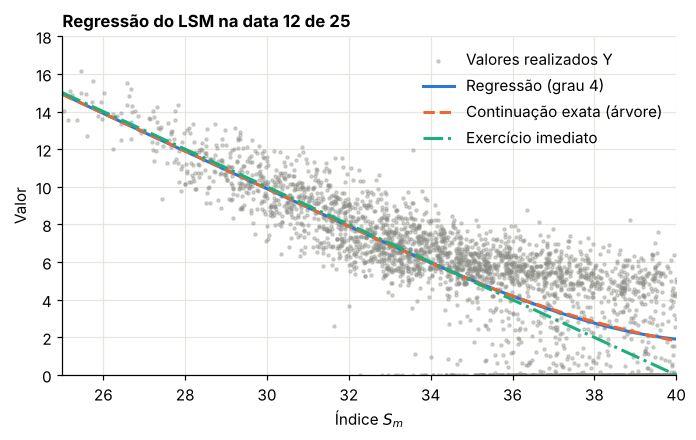

Maior erro da regressão na faixa 28 a 40: 0,090
OK — a regressão aproxima bem o valor de continuação exato


In [4]:
def base(s, K, grau):
    return P.polyvander(s / K, grau)


M, grau = 25, 4
rng = np.random.default_rng(902)
S = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], M, 20_000, rng)
desc = np.exp(-PUT["r"] * PUT["T"] / M)
V = pay_put(S[-1])
m_alvo = 12
for m in range(M - 1, 0, -1):
    Y = desc * V
    h = pay_put(S[m])
    itm = h > 0
    coef = np.linalg.lstsq(base(S[m][itm], 40.0, grau), Y[itm], rcond=None)[0]
    C = P.polyval(S[m] / 40.0, coef)
    if m == m_alvo:
        S_alvo, Y_alvo, coef_alvo, itm_alvo = S[m].copy(), Y.copy(), coef.copy(), itm.copy()
    V = np.where(itm & (h > C), h, Y)

# Valor de continuação exato na data m_alvo, pela árvore
_, tab = arvore_bermudana(pay_put, datas=M, guardar=True, **p_)
fator, N = 200, M * 200
dt_f = PUT["T"] / N
u_f = np.exp(PUT["sig"] * np.sqrt(dt_f))
d_f = 1 / u_f
q_f = (np.exp(PUT["r"] * dt_f) - d_f) / (u_f - d_f)
_, Vn = tab[m_alvo + 1]
Vc = Vn.copy()
for _ in range(fator):
    Vc = np.exp(-PUT["r"] * dt_f) * (q_f * Vc[1:] + (1 - q_f) * Vc[:-1])
t_no = (m_alvo + 1) * fator - fator
j = np.arange(t_no + 1)
S_no = PUT["S0"] * u_f**j * d_f ** (t_no - j)

grade = np.linspace(25, 40, 200)
fig, ax = plt.subplots()
idx = np.where(itm_alvo)[0][:3000]
ax.scatter(S_alvo[idx], Y_alvo[idx], s=4, color=CINZA, alpha=0.35, label="Valores realizados Y")
ax.plot(grade, P.polyval(grade / 40.0, coef_alvo), color=AZUL, label="Regressão (grau 4)")
ax.plot(grade, np.interp(grade, S_no, Vc), color=LARANJA, ls="--", label="Continuação exata (árvore)")
ax.plot(grade, pay_put(grade), color=VERDE, ls="-.", label="Exercício imediato")
ax.set_xlim(25, 40)
ax.set_ylim(0, 18)
ax.set_title(f"Regressão do LSM na data {m_alvo} de {M}")
ax.set_xlabel("Índice $S_m$")
ax.set_ylabel("Valor")
ax.legend()
plt.show()

erro_reg = np.abs(P.polyval(grade / 40.0, coef_alvo) - np.interp(grade, S_no, Vc))
print("Maior erro da regressão na faixa 28 a 40:", f3(float(erro_reg[grade >= 28].max())))
ok(erro_reg[grade >= 28].max() < 0.1, "a regressão aproxima bem o valor de continuação exato")

**Leitura.** Os pontos estão muito espalhados, porque cada $Y$ é o resultado de uma única trajetória. Mesmo assim, a média condicional, que é o que a regressão recupera, coincide com a curva exata. A decisão de exercer está no cruzamento das curvas azul e verde.

### 3.3 Dois vieses de sinais opostos

**Viés para baixo.** A regra de exercício estimada é, no máximo, tão boa quanto a ótima. Qualquer regra de exercício avaliada em trajetórias **novas** é um tempo de parada legítimo, e seu valor esperado não pode superar o ótimo. É o **limite inferior**.

**Viés para cima (dentro da amostra).** Se a mesma amostra serve para ajustar a regressão e para avaliar, a regra se adapta ao ruído daquela amostra, uma pequena dose da clarividência da Seção 2. Com poucas trajetórias e muitas funções-base, o resultado pode até superar o valor verdadeiro.

A solução, como o livro sugere, é separar: $I_1$ trajetórias para estimar os coeficientes e $I_2$ trajetórias novas para avaliar.

In [5]:
def lsm_regressoes(S, pay, K, r, T, grau, so_itm=True):
    """Passo para trás do LSM. Devolve os coeficientes (regra de exercício), os coeficientes em todas as trajetórias (função valor) e o valor dentro da amostra."""
    M = S.shape[0] - 1
    desc = np.exp(-r * T / M)
    V = pay(S[-1])
    regra, fval = [None] * (M + 1), [None] * (M + 1)
    for m in range(M - 1, 0, -1):
        Y = desc * V
        h = pay(S[m])
        sel = h > 0 if so_itm else np.ones_like(h, bool)
        x = S[m] / K
        faixa = (x.min(), x.max())
        c = np.linalg.lstsq(P.polyvander(x[sel], grau), Y[sel], rcond=None)[0]
        c_tudo = np.linalg.lstsq(P.polyvander(x, grau), Y, rcond=None)[0]
        regra[m], fval[m] = (c, faixa, so_itm), (c_tudo, faixa)
        C = P.polyval(x, c)
        V = np.where((h > 0) & (h > C) if so_itm else (h > C), h, Y)
    return regra, fval, float(desc * V.mean())


def continuacao(regra, m, s, K):
    c, faixa, _ = regra[m]
    return P.polyval(s / K, c)


def lsm_fora_amostra(S, pay, K, r, T, regra):
    """Aplica a regra de exercício a trajetórias novas: limite inferior."""
    M, I = S.shape[0] - 1, S.shape[1]
    dt = T / M
    valor = np.zeros(I)
    vivo = np.ones(I, bool)
    for m in range(1, M + 1):
        h = pay(S[m])
        if m < M:
            exerce = vivo & (h > 0) & (h > continuacao(regra, m, S[m], K))
        else:
            exerce = vivo & (h > 0)
        valor[exerce] = np.exp(-r * m * dt) * h[exerce]
        vivo &= ~exerce
    return float(valor.mean()), float(valor.std(ddof=1) / np.sqrt(I))


rng = np.random.default_rng(903)
linhas = []
for I1, grau in [(200, 8), (1_000, 8), (16_384, 8), (100_000, 4)]:
    dentro, fora = [], []
    for _ in range(20):
        S1 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, I1, rng)
        regra, _, v_in = lsm_regressoes(S1, pay_put, 40.0, PUT["r"], PUT["T"], grau)
        S2 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 50_000, rng)
        dentro.append(v_in)
        fora.append(lsm_fora_amostra(S2, pay_put, 40.0, PUT["r"], PUT["T"], regra)[0])
    linhas.append({"Trajetórias de regressão I1": str(I1), "Grau": grau, "Dentro da amostra: média": float(np.mean(dentro)), "Fora da amostra: média": float(np.mean(fora)), "Referência bermudana": ref[("put", 25)]})
vies = pd.DataFrame(linhas)
tabela(vies)
ok(vies["Dentro da amostra: média"].iloc[0] > vies["Fora da amostra: média"].iloc[0] + 0.03, "com poucas trajetórias, a estimativa dentro da amostra fica acima da de fora")
ok((vies["Fora da amostra: média"] < ref[("put", 25)] + 0.01).all(), "fora da amostra, a estimativa não ultrapassa a referência (é um limite inferior)")

,Trajetórias de regressão I1,Grau,Dentro da amostra: média,Fora da amostra: média,Referência bermudana
0,200,8,"4,854","4,259","4,469"
1,1000,8,"4,537","4,426","4,469"
2,16384,8,"4,470","4,465","4,469"
3,100000,4,"4,469","4,466","4,469"


OK — com poucas trajetórias, a estimativa dentro da amostra fica acima da de fora
OK — fora da amostra, a estimativa não ultrapassa a referência (é um limite inferior)


### Laboratório 3.2 — Funções-base e regressão só dentro do dinheiro

Usamos $I_1 = 16.384$ trajetórias para estimar a regra e $I_2 = 100.000$ para avaliá-la.

In [6]:
rng = np.random.default_rng(904)
S1 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 16_384, rng)
S2 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 100_000, rng)
linhas = []
for so_itm in [True, False]:
    for grau in [1, 2, 3, 5, 8]:
        regra, _, _ = lsm_regressoes(S1, pay_put, 40.0, PUT["r"], PUT["T"], grau, so_itm)
        v, ep = lsm_fora_amostra(S2, pay_put, 40.0, PUT["r"], PUT["T"], regra)
        linhas.append({"Regressão": "Só dentro do dinheiro" if so_itm else "Todas as trajetórias", "Grau": grau, "Valor (fora da amostra)": v, "Erro-padrão": ep, "Distância à bermudana": v - ref[("put", 25)]})
bas = pd.DataFrame(linhas)
tabela(bas)
ok(bas.query("Regressão == 'Só dentro do dinheiro' and Grau == 3")["Distância à bermudana"].abs().iloc[0] < 0.02, "com regressão só dentro do dinheiro e grau 3, o LSM fica a menos de 0,02 da bermudana")
ok(bas.query("Grau == 1")["Valor (fora da amostra)"].max() < bas.query("Grau == 3")["Valor (fora da amostra)"].min(), "uma base muito pobre (reta) produz uma regra de exercício pior")

,Regressão,Grau,Valor (fora da amostra),Erro-padrão,Distância à bermudana
0,Só dentro do dinheiro,1,"4,417","0,010","-0,052"
1,Só dentro do dinheiro,2,"4,460","0,010","-0,009"
2,Só dentro do dinheiro,3,"4,464","0,009","-0,005"
3,Só dentro do dinheiro,5,"4,467","0,009","-0,003"
4,Só dentro do dinheiro,8,"4,465","0,009","-0,004"
5,Todas as trajetórias,1,"4,439","0,010","-0,030"
6,Todas as trajetórias,2,"4,458","0,009","-0,011"
7,Todas as trajetórias,3,"4,462","0,009","-0,007"
8,Todas as trajetórias,5,"4,466","0,009","-0,003"
9,Todas as trajetórias,8,"4,466","0,009","-0,003"


OK — com regressão só dentro do dinheiro e grau 3, o LSM fica a menos de 0,02 da bermudana
OK — uma base muito pobre (reta) produz uma regra de exercício pior


---
## 4. A formulação dual: um limite superior

**Livro: §7.3.1 e Algoritmo 2**

O LSM dá um limite inferior, mas não diz **o quanto** está abaixo. Haugh e Kogan (2004) e Rogers (2002) mostraram como obter um limite superior.

### 4.1 Dedução

Trabalhe com valores descontados, $\tilde h_m = e^{-rt_m}h(S_m)$. Seja $\mathcal{M}$ qualquer martingale com $\mathcal{M}_0 = 0$.

**Passo 1.** Para qualquer tempo de parada $\tau$, o teorema de parada opcional dá $\mathbb{E}[\mathcal{M}_\tau] = \mathcal{M}_0 = 0$. Logo,

$$\mathbb{E}\big[\tilde h_\tau\big] = \mathbb{E}\big[\tilde h_\tau - \mathcal{M}_\tau\big].$$

**Passo 2.** O valor em $\tau$ não supera o maior valor da trajetória:

$$\mathbb{E}\big[\tilde h_\tau - \mathcal{M}_\tau\big] \le \mathbb{E}\Big[\max_m\big(\tilde h_m - \mathcal{M}_m\big)\Big].$$

**Passo 3.** O lado direito não depende de $\tau$. Tomando o supremo à esquerda:

$$\boxed{V_0 \le \mathbb{E}\Big[\max_m\big(\tilde h_m - \mathcal{M}_m\big)\Big]\quad\text{para todo martingale } \mathcal{M}.}$$

**Passo 4: a igualdade.** Tome o martingale da decomposição de Doob da envoltória de Snell, $\tilde V_m = V_0 + \mathcal{M}^*_m - A_m$, com $A$ crescente. Como $\tilde V$ fica acima de $\tilde h$:

$$\tilde h_m - \mathcal{M}^*_m \le \tilde V_m - \mathcal{M}^*_m = V_0 - A_m \le V_0.$$

O máximo é, portanto, no máximo $V_0$, e a desigualdade vira igualdade. Mais do que isso: **com o martingale ótimo, o estimador tem variância zero**. Toda trajetória dá exatamente $V_0$.

### 4.2 Como construir o martingale na prática

Não conhecemos $\mathcal{M}^*$, mas temos uma aproximação da função valor pelo LSM: $\hat V_m(s) = \max[h(s), \hat C_m(s)]$. Construímos o martingale pelos seus incrementos:

$$\mathcal{M}_m = \mathcal{M}_{m-1} + e^{-rt_m}\Big(\hat V_m(S_m) - \mathbb{E}\big[\hat V_m(S_m)\,\big|\,S_{m-1}\big]\Big).$$

Subtrair a esperança condicional garante que é um martingale, **seja qual for a qualidade de $\hat V$**. Uma $\hat V$ ruim dá um limite superior folgado, mas válido.

Resta calcular a esperança condicional. O livro faz uma **simulação aninhada**: $J$ sucessores de cada ponto. Num modelo de um fator, há uma alternativa sem ruído: a **quadratura de Gauss-Hermite**. Com $n$ nós $x_k$ e pesos $w_k$ da normal padrão,

$$\mathbb{E}\big[\hat V(S_m)\,\big|\,S_{m-1}\big] \approx \sum_{k=1}^{n}w_k\,\hat V\Big(S_{m-1}e^{(r - \frac12\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,x_k}\Big).$$

**Por que isso importa?** O ruído da simulação aninhada entra dentro do máximo. Pela desigualdade de Jensen, $\mathbb{E}[\max(\cdot)]$ cresce com o ruído: o limite superior fica viesado para cima, e tanto mais quanto menor $J$.

**Cuidado com a função valor fora do dinheiro.** O limite superior usa $\hat V$ em todo lugar, inclusive em regiões em que a regressão só dentro do dinheiro não tem dados e um polinômio de grau 8 extrapola de forma descontrolada. Por isso usamos a regressão em todas as trajetórias para $\hat V$, limitamos $x$ à faixa observada e truncamos $\hat C$ em zero.

### Laboratório 4.1 — Com a função valor exata, o limite é exato

Primeiro, um teste de sanidade: usamos como $\hat V$ o valor exato da árvore.

In [7]:
def dual(S, pay, r, T, sig, Vf, J=None, rng=None, n_gh=40):
    """Limite superior dual. Com J, esperança condicional por simulação aninhada; sem J, por Gauss-Hermite."""
    M, I = S.shape[0] - 1, S.shape[1]
    dt = T / M
    if J is None:
        x, w = np.polynomial.hermite_e.hermegauss(n_gh)
        w = w / w.sum()
    Mt = np.zeros(I)
    U = np.full(I, -np.inf)
    for m in range(1, M + 1):
        d = np.exp(-r * m * dt)
        if J is None:
            suc = S[m - 1][:, None] * np.exp((r - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * x)
            esp = Vf(m, suc.ravel()).reshape(I, -1) @ w
        else:
            z = rng.standard_normal((I, J))
            suc = S[m - 1][:, None] * np.exp((r - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * z)
            esp = Vf(m, suc.ravel()).reshape(I, J).mean(axis=1)
        Mt = Mt + d * (Vf(m, S[m]) - esp)
        U = np.maximum(U, d * pay(S[m]) - Mt)
    return float(U.mean()), float(U.std(ddof=1) / np.sqrt(I)), float(U.std(ddof=1))


v_arv, tab25 = arvore_bermudana(pay_put, datas=25, fator=40, guardar=True, **p_)
V_exata = lambda m, s: np.interp(np.log(s), *tab25[m])

rng = np.random.default_rng(905)
S3 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 2_000, rng, momentos=False)
linhas = []
for J in [10, 50, 500, None]:
    v, ep, dp = dual(S3, pay_put, PUT["r"], PUT["T"], PUT["sig"], V_exata, J=J, rng=rng)
    linhas.append({"Esperança condicional": f"Aninhada, J = {J}" if J else "Gauss-Hermite (40 nós)", "Limite superior": v, "Desvio-padrão por trajetória": dp, "Folga sobre a bermudana": v - v_arv})
ex = pd.DataFrame(linhas)
tabela(ex)
ok(ex["Folga sobre a bermudana"].iloc[0] > ex["Folga sobre a bermudana"].iloc[2] > ex["Folga sobre a bermudana"].iloc[3] - 1e-4, "a folga cai quando a esperança condicional fica mais precisa")
ok(abs(ex["Folga sobre a bermudana"].iloc[-1]) < 0.003 and ex["Desvio-padrão por trajetória"].iloc[-1] < 0.05, "com função valor exata e sem ruído, o limite é exato e quase sem variância")

,Esperança condicional,Limite superior,Desvio-padrão por trajetória,Folga sobre a bermudana
0,"Aninhada, J = 10","5,059","0,948","0,589"
1,"Aninhada, J = 50","4,637","0,394","0,167"
2,"Aninhada, J = 500","4,492","0,126","0,023"
3,Gauss-Hermite (40 nós),"4,469","0,005","-0,000"


OK — a folga cai quando a esperança condicional fica mais precisa
OK — com função valor exata e sem ruído, o limite é exato e quase sem variância


**Leitura.** A primeira linha mostra o tamanho do problema: com $J = 10$, o limite superior fica mais de meio real acima do valor verdadeiro, e isso **com a função valor perfeita**. A folga vem inteira do ruído aninhado. Com a quadratura, ela desaparece, e o desvio por trajetória vai a quase zero, como o Passo 4 previa.

### Laboratório 4.2 — O intervalo completo para a put

Agora o caso real: função valor estimada pelo LSM.

In [8]:
def funcao_valor(fval, pay, K, M):
    def Vf(m, s):
        h = pay(s)
        if m == M:
            return h
        c, (a, b) = fval[m]
        return np.maximum(h, np.maximum(P.polyval(np.clip(s / K, a, b), c), 0.0))
    return Vf


rng = np.random.default_rng(906)
S1 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 16_384, rng)
S2 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 100_000, rng)
S3 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 2_000, rng, momentos=False)
linhas = []
for grau in [3, 5, 8]:
    regra, fval, _ = lsm_regressoes(S1, pay_put, 40.0, PUT["r"], PUT["T"], grau)
    lo, ep_lo = lsm_fora_amostra(S2, pay_put, 40.0, PUT["r"], PUT["T"], regra)
    Vf = funcao_valor(fval, pay_put, 40.0, 25)
    up_a, ep_a, _ = dual(S3, pay_put, PUT["r"], PUT["T"], PUT["sig"], Vf, J=50, rng=rng)
    up_q, ep_q, _ = dual(S3, pay_put, PUT["r"], PUT["T"], PUT["sig"], Vf)
    linhas.append({"Grau": grau, "LSM (inferior)": lo, "Dual aninhado J=50": up_a, "Dual Gauss-Hermite": up_q, "Largura do intervalo (quadratura)": up_q - lo})
du = pd.DataFrame(linhas)
tabela(du)
print("Referência bermudana de 25 datas:", f3(ref[("put", 25)]))
ok((du["LSM (inferior)"] < ref[("put", 25)] + 0.01).all() and (du["Dual Gauss-Hermite"] > ref[("put", 25)] - 0.01).all(), "a bermudana fica entre os dois limites")
ok(du["Largura do intervalo (quadratura)"].iloc[-1] < 0.05, "com grau 8 e quadratura, o intervalo tem largura menor que 0,05")
ok((du["Dual aninhado J=50"] > du["Dual Gauss-Hermite"] + 0.05).all(), "a simulação aninhada com J=50 infla o limite superior")

,Grau,LSM (inferior),Dual aninhado J=50,Dual Gauss-Hermite,Largura do intervalo (quadratura)
0,3,"4,475","4,713","4,568","0,093"
1,5,"4,471","4,675","4,508","0,038"
2,8,"4,470","4,683","4,496","0,026"


Referência bermudana de 25 datas: 4,469
OK — a bermudana fica entre os dois limites
OK — com grau 8 e quadratura, o intervalo tem largura menor que 0,05
OK — a simulação aninhada com J=50 infla o limite superior


---
## 5. Reproduzindo a Tabela 7.1, com a referência certa

O livro roda cada configuração 25 vezes. Fazemos o mesmo para $M = 25$ e $M = 50$, com os parâmetros do livro para o dual aninhado ($I_1 = 16.384$, $J = 50$), e acrescentamos o dual por quadratura.

Tempo total: 6,405 s


,M,LSM: média,Livro LSM,Dual J=50: média,Livro dual,Dual quadratura: média,Bermudana,Americana
0,25,"4,468","4,452","4,662","4,651","4,493","4,469","4,487"
1,50,"4,466","4,470","4,708","4,595","4,514","4,478","4,487"


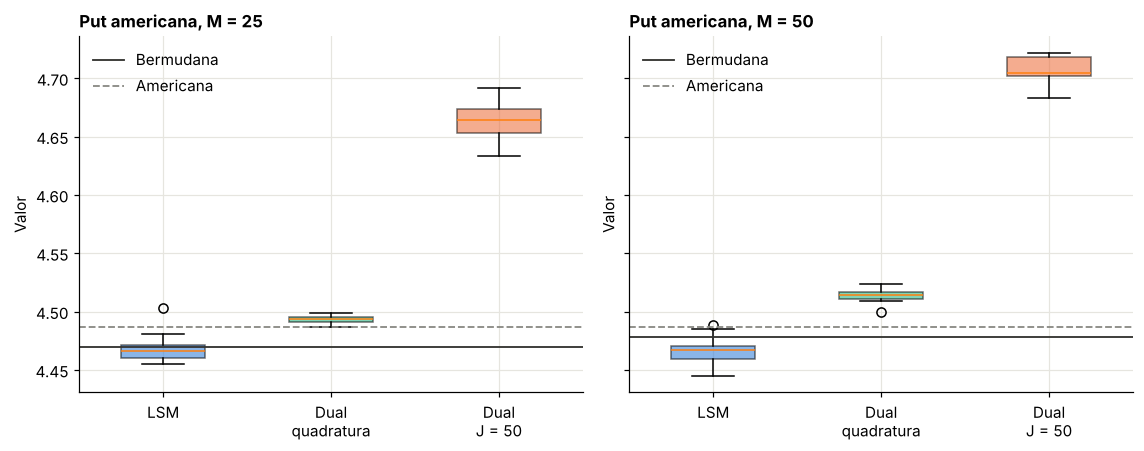

OK — M = 25: o LSM fica a menos de 0,02 da bermudana
OK — M = 25: a quadratura corta a folga do dual pela metade ou mais
OK — M = 50: o LSM fica a menos de 0,02 da bermudana
OK — M = 50: a quadratura corta a folga do dual pela metade ou mais


In [9]:
rng = np.random.default_rng(907)
corridas = {}
t0 = perf_counter()
for M in [25, 50]:
    res = {"LSM": [], "Dual J=50": [], "Dual quadratura": []}
    for _ in range(15):
        S1 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], M, 16_384, rng)
        regra, fval, _ = lsm_regressoes(S1, pay_put, 40.0, PUT["r"], PUT["T"], 8)
        S2 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], M, 20_000, rng)
        res["LSM"].append(lsm_fora_amostra(S2, pay_put, 40.0, PUT["r"], PUT["T"], regra)[0])
        S3 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], M, 1_000, rng, momentos=False)
        Vf = funcao_valor(fval, pay_put, 40.0, M)
        res["Dual J=50"].append(dual(S3, pay_put, PUT["r"], PUT["T"], PUT["sig"], Vf, J=50, rng=rng)[0])
        res["Dual quadratura"].append(dual(S3, pay_put, PUT["r"], PUT["T"], PUT["sig"], Vf)[0])
    corridas[M] = res
print("Tempo total:", f3(perf_counter() - t0), "s")

linhas = []
livro = {25: (4.452, 4.651), 50: (4.470, 4.595)}
for M, res in corridas.items():
    linhas.append({"M": M, "LSM: média": float(np.mean(res["LSM"])), "Livro LSM": livro[M][0], "Dual J=50: média": float(np.mean(res["Dual J=50"])), "Livro dual": livro[M][1], "Dual quadratura: média": float(np.mean(res["Dual quadratura"])), "Bermudana": ref[("put", M)], "Americana": am_put})
t71 = pd.DataFrame(linhas)
tabela(t71)

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for ax, M in zip(eixos, [25, 50]):
    dados = [corridas[M]["LSM"], corridas[M]["Dual quadratura"], corridas[M]["Dual J=50"]]
    caixa = ax.boxplot(dados, tick_labels=["LSM", "Dual\nquadratura", "Dual\nJ = 50"], patch_artist=True, widths=0.5)
    for b, cor in zip(caixa["boxes"], [AZUL, VERDE, LARANJA]):
        b.set_facecolor(cor)
        b.set_alpha(0.55)
    ax.axhline(ref[("put", M)], color="#333330", lw=1.2, label="Bermudana")
    ax.axhline(am_put, color=CINZA, lw=1.2, ls="--", label="Americana")
    ax.set_title(f"Put americana, M = {M}")
    ax.set_ylabel("Valor")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

for M in [25, 50]:
    ok(abs(np.mean(corridas[M]["LSM"]) - ref[("put", M)]) < 0.02, f"M = {M}: o LSM fica a menos de 0,02 da bermudana")
    ok(np.mean(corridas[M]["Dual quadratura"]) - ref[("put", M)] < 0.5 * (np.mean(corridas[M]["Dual J=50"]) - ref[("put", M)]), f"M = {M}: a quadratura corta a folga do dual pela metade ou mais")

**Leitura.** Duas correções à leitura do livro:

1. Parte da "diferença" de −0,034 atribuída ao LSM com $M = 25$ é a diferença entre americana e bermudana, de cerca de 0,017. Medido contra a referência correta, o LSM erra bem pouco.
2. A distância do dual, de 0,165, vem principalmente do ruído da simulação aninhada. Com quadratura, o limite superior fica perto do valor verdadeiro.

---
## 6. Um payoff difícil: o short condor

**Livro: §7.4.2**

$$h(s) = \min\big[40,\ \max(90 - s, 0) + \max(s - 110, 0)\big].$$

O payoff é **não convexo**, com duas quinas e um platô. Polinômios simples têm dificuldade de aproximá-lo, e o livro conclui que a convergência do LSM é fraca. Como o payoff é positivo quase em todo lugar, regredimos em todas as trajetórias.

### Laboratório 6.1 — O condor com a referência certa

In [10]:
rng = np.random.default_rng(908)
linhas = []
for M in [25, 50]:
    S1 = simular(CONDOR["S0"], CONDOR["r"], CONDOR["sig"], CONDOR["T"], M, 16_384, rng)
    S2 = simular(CONDOR["S0"], CONDOR["r"], CONDOR["sig"], CONDOR["T"], M, 50_000, rng)
    S3 = simular(CONDOR["S0"], CONDOR["r"], CONDOR["sig"], CONDOR["T"], M, 1_500, rng, momentos=False)
    for grau in [4, 8]:
        regra, fval, _ = lsm_regressoes(S1, pay_condor, 100.0, CONDOR["r"], CONDOR["T"], grau, so_itm=False)
        lo, _ = lsm_fora_amostra(S2, pay_condor, 100.0, CONDOR["r"], CONDOR["T"], regra)
        up, _, _ = dual(S3, pay_condor, CONDOR["r"], CONDOR["T"], CONDOR["sig"], funcao_valor(fval, pay_condor, 100.0, M))
        linhas.append({"M": M, "Grau": grau, "LSM (inferior)": lo, "Dual quadratura (superior)": up, "Bermudana": ref[("condor", M)], "LSM − bermudana": lo - ref[("condor", M)]})
con = pd.DataFrame(linhas)
tabela(con)
print("Livro: LSM médio de 25,977 (M=25) e 26,027 (M=50), comparado com 26,977.")
ok((con["LSM (inferior)"] <= con["Bermudana"] + 0.05).all() and (con["Dual quadratura (superior)"] >= con["Bermudana"] - 0.05).all(), "no condor, a bermudana também fica entre os limites")
ok(con.query("Grau == 8")["LSM − bermudana"].abs().max() < 0.3, "com grau 8, o LSM fica a menos de 0,3 da bermudana")

,M,Grau,LSM (inferior),Dual quadratura (superior),Bermudana,LSM − bermudana
0,25,4,"25,474","27,168","26,015","-0,541"
1,25,8,"25,878","26,288","26,015","-0,136"
2,50,4,"25,449","27,790","26,332","-0,884"
3,50,8,"26,128","26,593","26,332","-0,204"


Livro: LSM médio de 25,977 (M=25) e 26,027 (M=50), comparado com 26,977.
OK — no condor, a bermudana também fica entre os limites
OK — com grau 8, o LSM fica a menos de 0,3 da bermudana


**Leitura.** O livro mede uma diferença de cerca de −1,000 com $M = 25$. Mas a bermudana de 25 datas vale 26,015, e a americana, 26,977: **quase toda a diferença é efeito das datas de exercício**, e não fraqueza do LSM. No condor, o efeito é grande porque a volatilidade é alta (50%) e o payoff tem um teto, o que dá muito valor a exercer exatamente no momento certo.

---
## 7. Fronteira de exercício

A regra do LSM define uma fronteira: em cada data, o maior nível do índice em que se exerce. Comparamos com a fronteira exata da árvore.

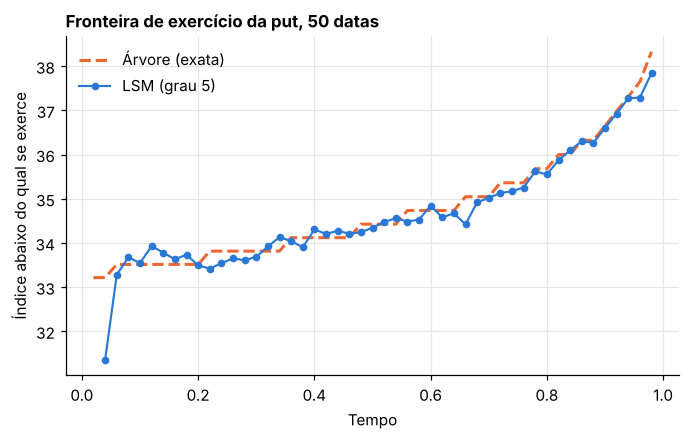

Diferença média entre as fronteiras: 0,203
OK — a fronteira do LSM fica perto da exata


In [11]:
rng = np.random.default_rng(909)
M = 50
S1 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], M, 50_000, rng)
regra, _, _ = lsm_regressoes(S1, pay_put, 40.0, PUT["r"], PUT["T"], 5)
grade = np.linspace(20, 40, 4001)
fr_lsm = []
for m in range(1, M):
    exerce = (pay_put(grade) > 0) & (pay_put(grade) > continuacao(regra, m, grade, 40.0))
    fr_lsm.append(grade[exerce].max() if exerce.any() else np.nan)

_, tab50 = arvore_bermudana(pay_put, datas=M, fator=40, guardar=True, **p_)
fr_arv = []
N, fator = M * 40, 40
dt_f = PUT["T"] / N
u_f = np.exp(PUT["sig"] * np.sqrt(dt_f))
d_f = 1 / u_f
q_f = (np.exp(PUT["r"] * dt_f) - d_f) / (u_f - d_f)
for m in range(1, M):
    _, Vn = tab50[m + 1]
    Vc = Vn.copy()
    for _ in range(fator):
        Vc = np.exp(-PUT["r"] * dt_f) * (q_f * Vc[1:] + (1 - q_f) * Vc[:-1])
    S_no = PUT["S0"] * u_f ** np.arange(m * fator + 1) * d_f ** (m * fator - np.arange(m * fator + 1))
    exerce = pay_put(S_no) > Vc + 1e-12
    fr_arv.append(S_no[exerce].max() if exerce.any() else np.nan)

ts = np.arange(1, M) / M
fig, ax = plt.subplots()
ax.plot(ts, fr_arv, color=LARANJA, ls="--", label="Árvore (exata)")
ax.plot(ts, fr_lsm, color=AZUL, marker="o", markersize=4, lw=1.4, label="LSM (grau 5)")
ax.set_title("Fronteira de exercício da put, 50 datas")
ax.set_xlabel("Tempo")
ax.set_ylabel("Índice abaixo do qual se exerce")
ax.legend()
plt.show()

dif = np.nanmean(np.abs(np.array(fr_lsm) - np.array(fr_arv)))
print("Diferença média entre as fronteiras:", f3(float(dif)))
ok(dif < 0.5, "a fronteira do LSM fica perto da exata")

Pequenos desvios na fronteira custam pouco: o valor perto dela é quase indiferente entre exercer e continuar. Esse é o motivo de o LSM funcionar bem mesmo com regressões imperfeitas.

---
## 8. Redução de variância

**Livro: §7.4.1**

O livro usa duas técnicas, que estudaremos no Módulo 12:

- **Variáveis antitéticas:** para cada sorteio $z$, usa-se também $-z$.
- **Casamento de momentos:** padronizam-se os sorteios de cada data para média 0 e variância 1 exatas.

### Laboratório 8.1 — Efeito no desvio entre corridas

In [12]:
rng = np.random.default_rng(910)
linhas = []
for nome, mm, an in [("Sem redução", False, False), ("Antitéticas", False, True), ("Casamento de momentos", True, False), ("As duas", True, True)]:
    vals = []
    for _ in range(30):
        S1 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 8_192, rng, momentos=mm, antiteticas=an)
        regra, _, _ = lsm_regressoes(S1, pay_put, 40.0, PUT["r"], PUT["T"], 5)
        S2 = simular(PUT["S0"], PUT["r"], PUT["sig"], PUT["T"], 25, 8_192, rng, momentos=mm, antiteticas=an)
        vals.append(lsm_fora_amostra(S2, pay_put, 40.0, PUT["r"], PUT["T"], regra)[0])
    linhas.append({"Técnica": nome, "Média": float(np.mean(vals)), "Desvio entre corridas": float(np.std(vals, ddof=1))})
vr = pd.DataFrame(linhas).set_index("Técnica")
tabela(vr.reset_index())
ok(vr.loc["Casamento de momentos", "Desvio entre corridas"] < vr.loc["Sem redução", "Desvio entre corridas"], "o casamento de momentos reduz o desvio entre corridas")

,Técnica,Média,Desvio entre corridas
0,Sem redução,"4,459","0,028"
1,Antitéticas,"4,461","0,023"
2,Casamento de momentos,"4,460","0,021"
3,As duas,"4,460","0,025"


OK — o casamento de momentos reduz o desvio entre corridas


**Atenção ao combinar as duas técnicas com a avaliação fora da amostra.** Com casamento de momentos, as trajetórias deixam de ser independentes entre si, e o erro-padrão calculado da forma usual deixa de ser exato. O desvio entre corridas, medido acima, é a forma segura de avaliar a precisão.

---
## 9. Síntese

- O valor americano é uma parada ótima; com $M$ datas, uma bermudana.
- Comparar o LSM com o valor americano mistura dois erros; a referência certa é a bermudana com as mesmas datas.
- Decidir com o futuro realizado superestima; decidir com a regressão é um tempo de parada legítimo.
- A regressão só decide; o valor guardado é o realizado.
- Fora da amostra, o LSM é limite inferior; dentro da amostra, pode ser viesado para cima.
- O dual dá um limite superior para qualquer martingale, e exato para o de Doob.
- O ruído da simulação aninhada infla o limite superior; com quadratura, o intervalo fica estreito.

## 10. Notas sobre o livro neste capítulo

| Local | Comentário |
|---|---|
| Tabelas 7.1 e 7.2 | a referência (árvore de 500 passos) é americana; os algoritmos estimam bermudanas de $M$ datas. Boa parte da "diferença" reportada, sobretudo no condor, é a diferença entre as duas |
| Tabela 7.2, nota | diz "American put option"; a tabela é do short condor |
| Tabela 7.1 e §7.4.1 | o espaçamento entre LSM e dual é atribuído ao algoritmo; ele vem sobretudo do ruído da simulação aninhada ($J = 50$), que infla o limite superior |
| Equações (7.8) a (7.12) | o martingale deve ser expresso em unidades descontadas, como $h$; o texto mistura $B_0(t)[h_t - \mathcal{M}_t]$ com um $\mathcal{M}^*$ formado por valores não descontados |
| Equação (7.11) | o máximo passa de $t \in \{\Delta t, \dots, T\}$ para $t \in \{0, \dots, T\}$ sem comentário |

## 11. Exercícios

**Exercício 1.** Por que a regra de exercício estimada, aplicada a trajetórias novas, define um tempo de parada?

<details><summary>Solução</summary>

A decisão em $t_m$ depende apenas de $S_m$ e de coeficientes calculados com outra amostra, independente das trajetórias avaliadas. Logo, $\{\tau \le t_m\}$ é determinado pela informação até $t_m$.
</details>

**Exercício 2.** No dual, o que acontece com o limite se usarmos $\mathcal{M} \equiv 0$?

<details><summary>Solução</summary>

O limite fica $\mathbb{E}[\max_m\tilde h_m]$: o valor de exercer no melhor momento de cada trajetória, com conhecimento perfeito do futuro. É o valor "clarividente" da Seção 2, um limite superior válido, mas muito folgado.
</details>

**Exercício 3.** Mostre que, com o martingale de Doob, $\tilde h_m - \mathcal{M}^*_m \le V_0$ em todas as datas e trajetórias.

<details><summary>Solução</summary>

$\tilde V_m = V_0 + \mathcal{M}^*_m - A_m$, com $A_m \ge 0$ e $\tilde V_m \ge \tilde h_m$. Logo, $\tilde h_m - \mathcal{M}^*_m \le \tilde V_m - \mathcal{M}^*_m = V_0 - A_m \le V_0$.
</details>

**Exercício 4.** Use a função `lsm_regressoes` numa call americana sem dividendos. O que o LSM deveria encontrar?

<details><summary>Solução</summary>

Que nunca vale a pena exercer antes do vencimento (Módulo 6). A regressão deve dar continuação sempre acima do exercício; o valor fica igual ao da europeia, a menos do ruído.
</details>

**Exercício 5.** Em modelos com várias variáveis de estado, como Heston, por que a quadratura de Gauss-Hermite fica mais difícil, e o que se pode fazer?

<details><summary>Solução</summary>

A esperança condicional passa a ser uma integral em várias dimensões, e o número de nós cresce exponencialmente. Pode-se usar quadratura esparsa, ou voltar à simulação aninhada com $J$ maior e ciente do viés para cima. O LSM, por sua vez, se adapta bem: basta incluir a variância nas funções-base.
</details>

In [13]:
print(f"Módulo 9 concluído: {_checks['n']} verificações aprovadas.")

Módulo 9 concluído: 22 verificações aprovadas.
